# NB8 — CV merge, paired tests, calibration (GeoGraphNet, EuroSAT-MS)
**Inputs (3 Datasets only):** NB9a folds 0-2 (`nb9a_cv_*_f012`), NB9a folds 3-4 (`nb9a_cv_*_f34`), NB9b (`nb9b_cv_*`). No GPU needed.
Outputs: `nb8_cv_summary.csv`, `nb8_paired_tests.csv`, `nb8_calibration.csv`, `nb8_perclass_f1.csv`, two figures.
Notes: folds share training data, so fold-level tests are only indicative (with 5 folds the smallest possible Wilcoxon p is 0.0625). The pooled McNemar uses all 27,000 test predictions (each patch is tested exactly once across the five folds) and is corrected with Holm. Temperature is fitted on each fold's validation split and applied to its test split.

In [1]:
# Cell 1: load and merge
import os, glob, json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import wilcoxon, binomtest
from scipy.optimize import minimize_scalar
from sklearn.metrics import f1_score, cohen_kappa_score
ROOT = os.environ.get("NB8_ROOT", "/kaggle/input"); OUT = os.environ.get("NB8_OUT", "/kaggle/working")
def find_one(name):
    hits = glob.glob(ROOT + "/**/" + name, recursive=True)
    assert len(hits) == 1, (name, hits)
    return hits[0]

cols = ["Exp", "Fold", "Acc", "Macro_F1", "Kappa", "ECE", "Best_Epoch", "Train_Min"]
res = pd.concat([pd.read_csv(find_one(n))[cols] for n in ["nb9a_cv_results_f012.csv", "nb9a_cv_results_f34.csv", "nb9b_cv_results.csv"]], ignore_index=True)
P = {}
for n in ["nb9a_cv_probs_f012.npz", "nb9a_cv_probs_f34.npz", "nb9b_cv_probs.npz"]:
    z = np.load(find_one(n))
    for k in z.files:
        if k in P and k.startswith("y_"): assert np.array_equal(P[k], z[k]), "label mismatch for " + k
        else: P[k] = z[k]
MODELS = [m for m in ["A1", "A3", "A4", "A5", "B1", "B2", "B3"] if (res.Exp == m).any()]
FOLDS = [0, 1, 2, 3, 4]
for m in MODELS:
    assert sorted(res[res.Exp == m].Fold.tolist()) == FOLDS, ("missing folds for", m)
    for k in FOLDS: assert f"test_{m}_f{k}" in P and f"val_{m}_f{k}" in P
print("models:", MODELS, "| rows:", len(res), "| prob keys:", len(P))
print("prob rows sum to 1 (sample):", P[f"test_{MODELS[0]}_f0"].sum(1)[:3])
ytest = np.concatenate([P[f"y_test_f{k}"] for k in FOLDS]); print("pooled test patches:", len(ytest))

models: ['A3', 'A4', 'A5', 'B1', 'B2', 'B3'] | rows: 30 | prob keys: 70
prob rows sum to 1 (sample): [0.9999999 0.9999999 1.       ]
pooled test patches: 27000


,Model,Acc,Macro_F1,Kappa,ECE,Train_Min
0,A3,98.793 ± 0.129,98.727 ± 0.140,0.987 ± 0.001,0.076 ± 0.001,37.432 ± 0.544
1,A4,98.870 ± 0.108,98.814 ± 0.111,0.987 ± 0.001,0.076 ± 0.002,37.846 ± 0.488
2,A5,98.778 ± 0.160,98.716 ± 0.164,0.986 ± 0.002,0.074 ± 0.001,37.848 ± 0.504
3,B1,98.474 ± 0.183,98.413 ± 0.192,0.983 ± 0.002,0.087 ± 0.002,10.762 ± 0.025
4,B2,98.241 ± 0.087,98.157 ± 0.084,0.980 ± 0.001,0.086 ± 0.003,11.140 ± 0.058
5,B3,98.818 ± 0.060,98.762 ± 0.062,0.987 ± 0.001,0.082 ± 0.001,6.734 ± 0.028


Exp,A3,A4,A5,B1,B2,B3
Fold,,,,,,
0,98.828,98.886,98.735,98.312,98.122,98.677
1,98.618,98.703,98.828,98.309,98.116,98.748
2,98.914,98.968,98.870,98.751,98.234,98.767
3,98.688,98.785,98.450,98.384,98.057,98.769
4,98.587,98.727,98.699,98.308,98.255,98.851


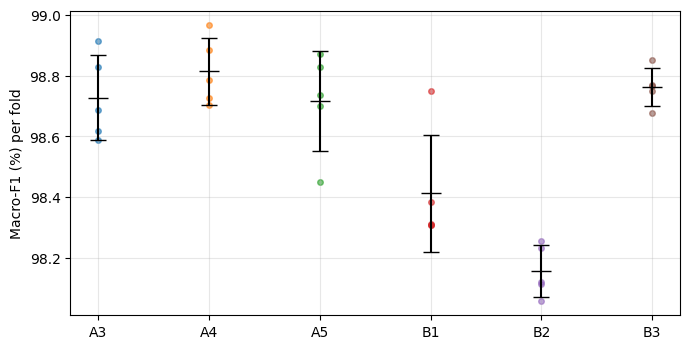

In [2]:
# Cell 2: cross-validation summary
agg = res.groupby("Exp")[["Acc", "Macro_F1", "Kappa", "ECE", "Train_Min"]].agg(["mean", "std"])
summary = pd.DataFrame({"Model": MODELS})
for c in ["Acc", "Macro_F1", "Kappa", "ECE", "Train_Min"]:
    summary[c] = [f"{agg.loc[m, (c, 'mean')]:.3f} ± {agg.loc[m, (c, 'std')]:.3f}" for m in MODELS]
display(summary); summary.to_csv(f"{OUT}/nb8_cv_summary.csv", index=False)
pv = res.pivot(index="Fold", columns="Exp", values="Macro_F1")[MODELS]; display(pv.round(3))
fig, ax = plt.subplots(figsize=(7, 3.6))
for i, m in enumerate(MODELS):
    ax.scatter([i] * 5, pv[m], s=16, alpha=.6); ax.errorbar(i, pv[m].mean(), yerr=pv[m].std(), fmt="_", color="k", capsize=6, ms=14)
ax.set_xticks(range(len(MODELS))); ax.set_xticklabels(MODELS); ax.set_ylabel("Macro-F1 (%) per fold"); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig(f"{OUT}/nb8_cv_macro_f1.png", dpi=150); plt.show()

In [3]:
# Cell 3: paired comparisons (per-fold Wilcoxon + pooled exact McNemar, Holm-corrected)
pairs = [("A4","A3"),("A5","A4"),("A5","A3"),("A3","B1"),("A4","B1"),("A5","B1"),("A3","B2"),("A4","B2"),("A5","B2"),
         ("A3","B3"),("A4","B3"),("A5","B3"),("B3","B1"),("B2","B1")]
pairs = [(a, b) for a, b in pairs if a in MODELS and b in MODELS]
def pooled_pred(m): return np.concatenate([P[f"test_{m}_f{k}"].argmax(1) for k in FOLDS])
PR = {m: pooled_pred(m) for m in MODELS}
rows = []
for a, b in pairs:
    d = (pv[a] - pv[b]).values
    try: pw = wilcoxon(d, method="exact").pvalue
    except Exception: pw = np.nan
    ra, rb = PR[a] == ytest, PR[b] == ytest; n10, n01 = int((ra & ~rb).sum()), int((~ra & rb).sum())
    pm = binomtest(min(n10, n01), n10 + n01, 0.5).pvalue if n10 + n01 > 0 else 1.0
    rows.append(dict(A=a, B=b, mean_diff_F1=d.mean(), folds_A_better=int((d > 0).sum()), wilcoxon_p=pw, A_right_B_wrong=n10, A_wrong_B_right=n01, mcnemar_p=pm))
pt = pd.DataFrame(rows)
order = np.argsort(pt.mcnemar_p.values); m_ = len(pt); holm = np.empty(m_); run = 0.0
for rank, i in enumerate(order):
    run = max(run, (m_ - rank) * pt.mcnemar_p.values[i]); holm[i] = min(1.0, run)
pt["mcnemar_p_holm"] = holm
pt = pt.round(4); display(pt); pt.to_csv(f"{OUT}/nb8_paired_tests.csv", index=False)
print("Note: with 5 folds the minimum possible Wilcoxon p is 0.0625.")

,A,B,mean_diff_F1,folds_A_better,wilcoxon_p,A_right_B_wrong,A_wrong_B_right,mcnemar_p,mcnemar_p_holm
0,A4,A3,0.0868,5,0.0625,138,117,0.2103,1.0000
1,A5,A4,-0.0974,1,0.3125,141,166,0.1707,1.0000
2,A5,A3,-0.0106,2,1.0000,144,148,0.8607,1.0000
3,A3,B1,0.3142,5,0.0625,283,197,0.0001,0.0009
4,A4,B1,0.4010,5,0.0625,292,185,0.0000,0.0000
5,A5,B1,0.3036,5,0.0625,282,200,0.0002,0.0017
6,A3,B2,0.5702,5,0.0625,279,130,0.0000,0.0000
7,A4,B2,0.6570,5,0.0625,304,134,0.0000,0.0000
8,A5,B2,0.5596,5,0.0625,278,133,0.0000,0.0000
9,A3,B3,-0.0354,2,1.0000,195,202,0.7634,1.0000


Note: with 5 folds the minimum possible Wilcoxon p is 0.0625.


In [4]:
# Cell 4: temperature scaling (fit on validation, apply to test), NLL / Brier / ECE
def softmax(z):
    z = z - z.max(1, keepdims=True); e = np.exp(z); return e / e.sum(1, keepdims=True)
def nll(p, y): return float(-np.log(np.clip(p[np.arange(len(y)), y], 1e-12, 1)).mean())
def brier(p, y): oh = np.eye(p.shape[1])[y]; return float(((p - oh) ** 2).sum(1).mean())
def ece(p, y, bins=15):
    conf, pred = p.max(1), p.argmax(1); acc = (pred == y).astype(float); e = 0.0; edges = np.linspace(0, 1, bins + 1)
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any(): e += m.mean() * abs(acc[m].mean() - conf[m].mean())
    return e
def logit(p): return np.log(np.clip(p, 1e-12, 1.0))         # log-probabilities equal logits up to a constant per row
def fit_T(pv_, yv_):
    lp = logit(pv_); r = minimize_scalar(lambda T: nll(softmax(lp / T), yv_), bounds=(0.05, 10), method="bounded"); return float(r.x)

crow = []; TS_P = {m: [] for m in MODELS}
for m in MODELS:
    for k in FOLDS:
        pvv, yv, ptt, yt = P[f"val_{m}_f{k}"], P[f"y_val_f{k}"], P[f"test_{m}_f{k}"], P[f"y_test_f{k}"]
        T = fit_T(pvv, yv); pts = softmax(logit(ptt) / T); TS_P[m].append(pts)
        assert (pts.argmax(1) == ptt.argmax(1)).all()
        crow.append(dict(Model=m, Fold=k, T=T, NLL_raw=nll(ptt, yt), NLL_ts=nll(pts, yt), Brier_raw=brier(ptt, yt), Brier_ts=brier(pts, yt),
                         ECE_raw=ece(ptt, yt), ECE_ts=ece(pts, yt)))
cal = pd.DataFrame(crow); cal.to_csv(f"{OUT}/nb8_calibration_per_fold.csv", index=False)
g = cal.groupby("Model")[["T", "NLL_raw", "NLL_ts", "Brier_raw", "Brier_ts", "ECE_raw", "ECE_ts"]].agg(["mean", "std"]).loc[MODELS]
calsum = pd.DataFrame({"Model": MODELS})
for c in ["T", "NLL_raw", "NLL_ts", "Brier_raw", "Brier_ts", "ECE_raw", "ECE_ts"]:
    calsum[c] = [f"{g.loc[m, (c, 'mean')]:.4f} ± {g.loc[m, (c, 'std')]:.4f}" for m in MODELS]
display(calsum); calsum.to_csv(f"{OUT}/nb8_calibration.csv", index=False)
print("T < 1 means the raw model was under-confident (label smoothing); accuracy is unchanged by temperature scaling.")

,Model,T,NLL_raw,NLL_ts,Brier_raw,Brier_ts,ECE_raw,ECE_ts
0,A3,0.6278 ± 0.0083,0.1207 ± 0.0035,0.0567 ± 0.0043,0.0261 ± 0.0018,0.0211 ± 0.0020,0.0764 ± 0.0005,0.0037 ± 0.0009
1,A4,0.6172 ± 0.0095,0.1185 ± 0.0026,0.0540 ± 0.0037,0.0252 ± 0.0015,0.0200 ± 0.0017,0.0765 ± 0.0016,0.0041 ± 0.0010
2,A5,0.6337 ± 0.0037,0.1178 ± 0.0040,0.0554 ± 0.0066,0.0255 ± 0.0024,0.0209 ± 0.0030,0.0742 ± 0.0007,0.0041 ± 0.0016
3,B1,0.5824 ± 0.0107,0.1373 ± 0.0046,0.0587 ± 0.0059,0.0336 ± 0.0021,0.0250 ± 0.0025,0.0866 ± 0.0024,0.0050 ± 0.0009
4,B2,0.5993 ± 0.0101,0.1430 ± 0.0038,0.0658 ± 0.0035,0.0366 ± 0.0016,0.0283 ± 0.0017,0.0861 ± 0.0034,0.0050 ± 0.0007
5,B3,0.6232 ± 0.0064,0.1273 ± 0.0016,0.0605 ± 0.0028,0.0268 ± 0.0008,0.0209 ± 0.0011,0.0816 ± 0.0014,0.0039 ± 0.0010


T < 1 means the raw model was under-confident (label smoothing); accuracy is unchanged by temperature scaling.


,A3,A4,A5,B1,B2,B3
AnnualCrop,98.37,98.60,98.19,98.06,97.86,98.45
Forest,99.58,99.72,99.68,99.62,99.42,99.45
HerbaceousVegetation,98.24,98.31,98.24,97.53,96.98,98.48
Highway,98.72,98.74,98.72,98.38,97.71,98.66
Industrial,99.16,99.14,99.06,98.92,98.96,98.98
Pasture,97.03,97.59,97.19,97.44,96.23,97.59
PermanentCrop,97.81,97.67,97.73,96.76,96.48,97.85
Residential,99.42,99.42,99.27,99.53,99.18,99.40
River,99.10,99.18,99.14,98.26,98.90,98.92
SeaLake,99.83,99.78,99.95,99.63,99.85,99.83


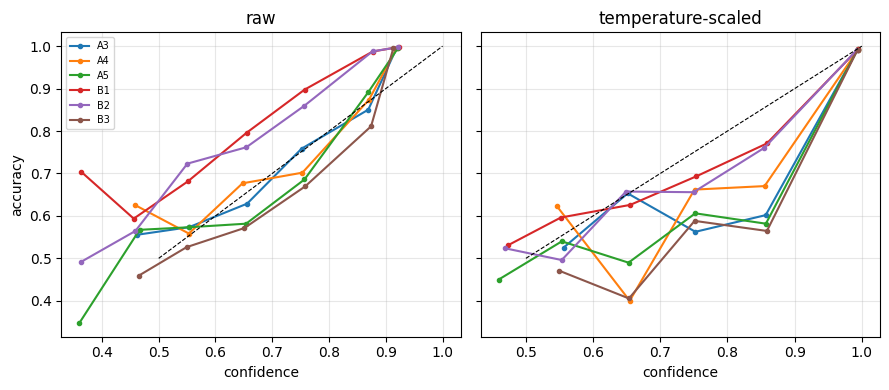

['__notebook__.ipynb', 'nb8_calibration.csv', 'nb8_calibration_per_fold.csv', 'nb8_cv_macro_f1.png', 'nb8_cv_summary.csv', 'nb8_paired_tests.csv', 'nb8_perclass_f1.csv', 'nb8_reliability.png']


In [5]:
# Cell 5: per-class F1 (pooled over folds) and reliability diagrams (pooled)
CLS = ["AnnualCrop", "Forest", "HerbaceousVegetation", "Highway", "Industrial", "Pasture", "PermanentCrop", "Residential", "River", "SeaLake"]
pc = pd.DataFrame({m: 100 * f1_score(ytest, PR[m], average=None) for m in MODELS}, index=CLS).round(2)
display(pc); pc.to_csv(f"{OUT}/nb8_perclass_f1.csv")
def reliab(p, y, bins=10):
    conf, pred = p.max(1), p.argmax(1); acc = (pred == y).astype(float); edges = np.linspace(0, 1, bins + 1); xs, ys = [], []
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.sum() >= 20: xs.append(conf[m].mean()); ys.append(acc[m].mean())
    return xs, ys
fig, ax = plt.subplots(1, 2, figsize=(9, 4), sharey=True)
for j, (title, get) in enumerate([("raw", lambda m: np.concatenate([P[f"test_{m}_f{k}"] for k in FOLDS])), ("temperature-scaled", lambda m: np.concatenate(TS_P[m]))]):
    for m in MODELS:
        xs, ys = reliab(get(m), ytest); ax[j].plot(xs, ys, marker="o", ms=3, label=m)
    ax[j].plot([0.5, 1], [0.5, 1], "k--", lw=.8); ax[j].set_title(title); ax[j].set_xlabel("confidence"); ax[j].grid(alpha=.3)
ax[0].set_ylabel("accuracy"); ax[0].legend(fontsize=7); plt.tight_layout(); plt.savefig(f"{OUT}/nb8_reliability.png", dpi=150); plt.show()
print(sorted(os.listdir(OUT)))